In [1]:
import pandas as pd
from pathlib import Path

RAW = Path("../data/raw/serpavi")
excel = list(RAW.glob("*.xls*"))[0]
print(excel.name)

hojas = pd.ExcelFile(excel).sheet_names
print(hojas)

2026-03_09_bd_SERPAVI_2011-2024 - DEFINITIVO WEB_v2.xlsx
['Metadatos', 'CCAA', 'Provincias', 'Municipios', 'Distritos', 'Secciones censales']


In [2]:
hoja_secciones = [h for h in hojas if "ecci" in h.lower()][0]   # la que contenga "secci"
print("Hoja:", hoja_secciones)

serpavi = pd.read_excel(excel, sheet_name=hoja_secciones, dtype=str)
print(serpavi.shape)
print(serpavi.columns.tolist()[:40])
serpavi.head()

Hoja: Secciones censales
(36293, 285)
['CPRO', 'LITPRO', 'CUMUN', 'LITMUN', 'CUSEC', 'BI_ALVHEPCO_TVC_11', 'BI_ALVHEPCO_TVU_11', 'ALQM2_LV_M_VC_11', 'ALQM2_LV_25_VC_11', 'ALQM2_LV_75_VC_11', 'ALQM2_LV_M_VU_11', 'ALQM2_LV_25_VU_11', 'ALQM2_LV_75_VU_11', 'ALQTBID12_M_VC_11', 'ALQTBID12_25_VC_11', 'ALQTBID12_75_VC_11', 'ALQTBID12_M_VU_11', 'ALQTBID12_25_VU_11', 'ALQTBID12_75_VU_11', 'SLVM2_M_VC_11', 'SLVM2_25_VC_11', 'SLVM2_75_VC_11', 'SLVM2_M_VU_11', 'SLVM2_25_VU_11', 'SLVM2_75_VU_11', 'BI_ALVHEPCO_TVC_12', 'BI_ALVHEPCO_TVU_12', 'ALQM2_LV_M_VC_12', 'ALQM2_LV_25_VC_12', 'ALQM2_LV_75_VC_12', 'ALQM2_LV_M_VU_12', 'ALQM2_LV_25_VU_12', 'ALQM2_LV_75_VU_12', 'ALQTBID12_M_VC_12', 'ALQTBID12_25_VC_12', 'ALQTBID12_75_VC_12', 'ALQTBID12_M_VU_12', 'ALQTBID12_25_VU_12', 'ALQTBID12_75_VU_12', 'SLVM2_M_VC_12']


,CPRO,LITPRO,CUMUN,LITMUN,CUSEC,BI_ALVHEPCO_TVC_11,BI_ALVHEPCO_TVU_11,ALQM2_LV_M_VC_11,ALQM2_LV_25_VC_11,ALQM2_LV_75_VC_11,...,ALQTBID12_75_VC_24,ALQTBID12_M_VU_24,ALQTBID12_25_VU_24,ALQTBID12_75_VU_24,SLVM2_M_VC_24,SLVM2_25_VC_24,SLVM2_75_VC_24,SLVM2_M_VU_24,SLVM2_25_VU_24,SLVM2_75_VU_24
0,01,Araba/Álava,01001,Alegría-Dulantzi,0100101001,NaN,NaN,NaN,NaN,NaN,...,601.64,701.92,563.47,794.5500000000001,89.19,70.09,101.12,138.42000000000002,118.5,155.68
1,01,Araba/Álava,01001,Alegría-Dulantzi,0100101002,NaN,NaN,NaN,NaN,NaN,...,624.62,NaN,NaN,NaN,80.89,67.91,91.66,NaN,NaN,NaN
2,01,Araba/Álava,01002,Amurrio,0100201001,NaN,NaN,NaN,NaN,NaN,...,601.64,NaN,NaN,NaN,90.83,82.22,101.8,NaN,NaN,NaN
3,01,Araba/Álava,01002,Amurrio,0100201002,NaN,NaN,NaN,NaN,NaN,...,618,NaN,NaN,NaN,95.10000000000001,87.53,102.66,NaN,NaN,NaN
4,01,Araba/Álava,01002,Amurrio,0100201003,NaN,NaN,NaN,NaN,NaN,...,661.8100000000001,NaN,NaN,NaN,86.26,81.47,100.77,NaN,NaN,NaN


In [3]:
madrid = serpavi[serpavi["CUMUN"] == "28079"].copy()
print("Secciones de Madrid en el SERPAVI:", len(madrid))

columnas = {
    "CUSEC": "cod_seccion_ine",
    "BI_ALVHEPCO_TVC_24": "n_viviendas",
    "ALQM2_LV_M_VC_24": "eur_m2",
    "ALQM2_LV_25_VC_24": "eur_m2_p25",
    "ALQM2_LV_75_VC_24": "eur_m2_p75",
    "ALQTBID12_M_VC_24": "eur_mes",
    "SLVM2_M_VC_24": "m2",
}
precios = madrid[list(columnas)].rename(columns=columnas)

num = [c for c in precios.columns if c != "cod_seccion_ine"]
precios[num] = precios[num].apply(pd.to_numeric, errors="coerce")

print(precios[num].describe().round(1))
print("\nSecciones sin precio:", precios["eur_m2"].isna().sum())

Secciones de Madrid en el SERPAVI: 2442
       n_viviendas  eur_m2  eur_m2_p25  eur_m2_p75  eur_mes      m2
count       2438.0  2421.0      2421.0      2421.0   2421.0  2421.0
mean         123.2    13.6        11.3        16.3    941.1    72.0
std           72.2     3.1         2.4         4.0    294.5    20.1
min            0.0     7.1         5.6         7.8    550.0    31.0
25%           73.0    11.2         9.5        13.2    749.7    58.0
50%          111.0    13.0        10.9        15.4    850.0    67.0
75%          159.0    16.0        13.1        19.3   1057.0    82.0
max          630.0    25.7        21.6        32.8   3095.8   211.0

Secciones sin precio: 21


In [4]:
import geopandas as gpd

PROCESSED = Path("../data/processed")
secciones = gpd.read_parquet(PROCESSED / "secciones.parquet")
barrios = gpd.read_parquet(PROCESSED / "barrios.parquet")

secc_precios = secciones.merge(precios, on="cod_seccion_ine", how="left", indicator=True)

print(secc_precios["_merge"].value_counts())
print("\nNuestras secciones con precio:", secc_precios["eur_m2"].notna().sum(), "de", len(secciones))

solo_serpavi = set(precios["cod_seccion_ine"]) - set(secciones["cod_seccion_ine"])
print("Códigos del SERPAVI que no están en nuestras secciones:", len(solo_serpavi))

_merge
both          2408
left_only       54
right_only       0
Name: count, dtype: int64

Nuestras secciones con precio: 2390 de 2462
Códigos del SERPAVI que no están en nuestras secciones: 34


In [5]:
import numpy as np

def media_ponderada(g, col):
    g = g.dropna(subset=[col, "n_viviendas"])
    if g["n_viviendas"].sum() == 0:
        return np.nan
    return np.average(g[col], weights=g["n_viviendas"])

con_precio = secc_precios.dropna(subset=["eur_m2"])

barrio_precios = con_precio.groupby("cod_barrio").apply(
    lambda g: pd.Series({
        "eur_m2": media_ponderada(g, "eur_m2"),
        "eur_mes": media_ponderada(g, "eur_mes"),
        "m2": media_ponderada(g, "m2"),
        "n_viviendas": g["n_viviendas"].sum(),
        "n_secciones_con_dato": len(g),
    })
).reset_index()

barrios_precio = barrios.merge(barrio_precios, on="cod_barrio", how="left")
print("Barrios sin precio:", barrios_precio["eur_m2"].isna().sum())
barrios_precio.sort_values("eur_m2", ascending=False)[["barrio", "distrito", "eur_m2", "eur_mes", "m2", "n_viviendas"]].head(10)

Barrios sin precio: 0


,barrio,distrito,eur_m2,eur_mes,m2,n_viviendas
69,Recoletos,Salamanca,21.586435,1699.150984,79.939541,1654.0
80,Castellana,Salamanca,20.860511,1556.253886,74.975824,1820.0
75,Almagro,Chamberí,19.229653,1409.462965,74.941339,2165.0
77,Trafalgar,Chamberí,18.990389,1091.050962,58.620818,3766.0
64,Justicia,Centro,18.961604,1184.244915,63.303733,2545.0
76,Lista,Salamanca,18.951807,1232.072100,64.612485,2547.0
122,El Plantío,Moncloa - Aravaca,18.909292,1896.916667,108.000000,90.0
82,Gaztambide,Chamberí,18.872945,1163.123857,64.322183,3647.0
71,Goya,Salamanca,18.801229,1243.919203,66.821522,3810.0
87,Ríos Rosas,Chamberí,18.778644,1210.299823,64.824395,4009.0


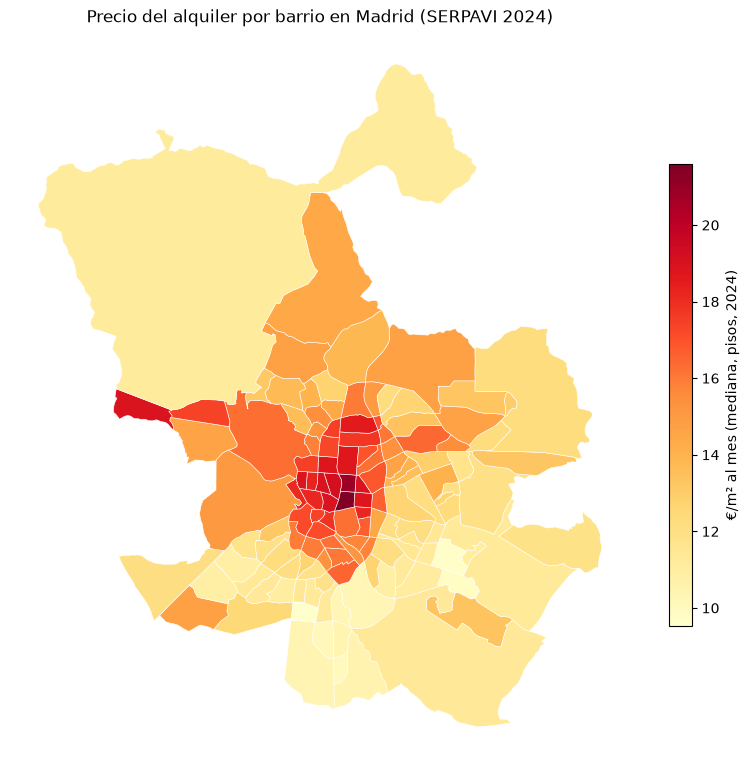

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))
barrios_precio.plot(
    column="eur_m2", cmap="YlOrRd", legend=True, ax=ax,
    edgecolor="white", linewidth=0.4,
    legend_kwds={"label": "€/m² al mes (mediana, pisos, 2024)", "shrink": 0.6},
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
)
ax.set_axis_off()
ax.set_title("Precio del alquiler por barrio en Madrid (SERPAVI 2024)")
plt.savefig("../data/interim/mapa_precios_barrios.png", dpi=150, bbox_inches="tight")

In [7]:
precios.to_parquet(PROCESSED / "precios_secciones_2024.parquet")
barrios_precio.to_parquet(PROCESSED / "barrios_precios.parquet")

In [8]:
barrios_precio["dato_fiable"] = barrios_precio["n_viviendas"] >= 300

print("Barrios con pocos datos (<300 viviendas):")
print(barrios_precio.loc[~barrios_precio["dato_fiable"], ["barrio", "distrito", "eur_m2", "n_viviendas"]]
      .sort_values("n_viviendas"))

Barrios con pocos datos (<300 viviendas):
             barrio               distrito     eur_m2  n_viviendas
122      El Plantío      Moncloa - Aravaca  18.909292         90.0
57           Atocha             Arganzuela  15.196078        103.0
130        El Pardo  Fuencarral - El Pardo  11.216197        150.0
129      Aeropuerto                Barajas  12.268519        167.0
111         Atalaya          Ciudad Lineal  17.009275        168.0
124  Fuentelarreina  Fuencarral - El Pardo  13.166288        177.0
51          Horcajo              Moratalaz  11.461021        210.0
